In [1]:
# Loads the temperature data for Math 50 Assignment 3 into dataframes `mbh`
# and `hadcrut`.
# Data is loaded directly from math50-data (raw GitHub URLs), so this
# notebook runs as-is in Colab.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [2]:
MBH_URL = "https://raw.githubusercontent.com/elevien/math50-data/main/data/mbh99-nh-temperature.csv"
HADCRUT_URL = "https://raw.githubusercontent.com/elevien/math50-data/main/data/hadcrut5-nh-annual.csv"


def load_mbh():
    # columns: year, recon (reconstructed temperature, 1000-1980),
    # inst (the thermometer record MBH used, 1902-1998) and
    # se (reported standard error of recon, 1000-1901).
    # Missing values are NaN.
    return pd.read_csv(MBH_URL)


def load_hadcrut(mbh):
    # columns: year, temp (HadCRUT5 Northern Hemisphere annual temperature,
    # 1850-present), shifted so that its 1902-1980 average matches mbh.inst
    # (the two records use different reference periods).
    out = pd.read_csv(HADCRUT_URL)[["year", "temp"]]
    both = out.merge(mbh, on="year")
    both = both[(both.year >= 1902) & (both.year <= 1980)]
    out["temp"] = out["temp"] - (both["temp"] - both["inst"]).mean()
    return out


mbh = load_mbh()
hadcrut = load_hadcrut(mbh)
mbh.head()

,year,recon,inst,se
0,1000,0.0659,NaN,0.240346
1,1001,-0.1241,NaN,0.240347
2,1002,-0.1208,NaN,0.240346
3,1003,-0.1801,NaN,0.240347
4,1004,-0.0711,NaN,0.240347


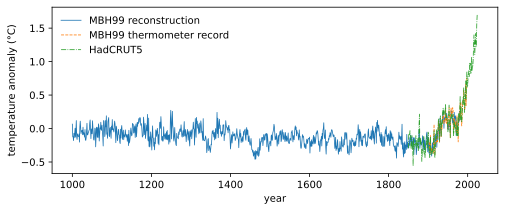

In [3]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(mbh.year, mbh.recon, lw=0.8, label="MBH99 reconstruction")
ax.plot(mbh.year, mbh.inst, "--", lw=0.8, label="MBH99 thermometer record")
ax.plot(hadcrut.year, hadcrut.temp, "-.", lw=0.8, label="HadCRUT5")
ax.set_xlabel("year")
ax.set_ylabel("temperature anomaly (°C)")
ax.legend(frameon=False)
plt.show()